# Análise de métricas sociais - Marca Exemplo

Notebook que lê o banco `data/metricas.sqlite` (gerado por `python -m pipeline.main`),
roda as consultas de `sql/consultas.sql` e responde perguntas de negócio com gráficos.

> Dados 100% sintéticos, inspirados em um fluxo real de relatórios de social media.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)

PASTA_IMG = Path("../docs/img")
PASTA_IMG.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect("../data/metricas.sqlite")

# Lê o arquivo de consultas e separa cada uma pelo título "-- Consulta N: ..."
texto = Path("../sql/consultas.sql").read_text(encoding="utf-8")
consultas = {}
for bloco in texto.split("\n-- Consulta ")[1:]:
    titulo, _, sql = bloco.partition("\n")
    numero = int(titulo.split(":")[0])
    consultas[numero] = sql


def rodar(numero):
    return pd.read_sql(consultas[numero], conn)


posts = pd.read_sql("SELECT * FROM posts", conn)
print(len(posts), "posts no banco")
print(posts.groupby("canal").size())

303 posts no banco
canal
Instagram    196
TikTok       107
dtype: int64


## 1. Qual formato engaja mais?

,canal,formato,posts,engajamento_medio
0,Instagram,Reels,58,0.0837
1,Instagram,Carrossel,53,0.0638
2,Instagram,Imagem,44,0.0367
3,Instagram,Stories,41,0.0223
4,TikTok,Vídeo,107,0.0833


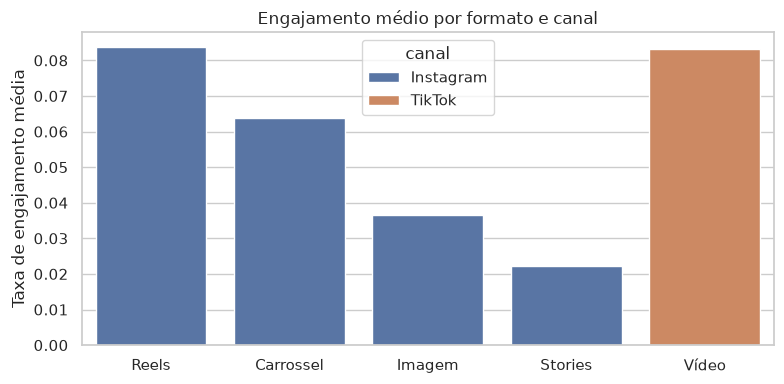

In [2]:
df = rodar(1)
display(df)

plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="formato", y="engajamento_medio", hue="canal")
plt.title("Engajamento médio por formato e canal")
plt.ylabel("Taxa de engajamento média")
plt.xlabel("")
plt.tight_layout()
plt.savefig(PASTA_IMG / "engajamento_por_formato.png", dpi=120)
plt.show()

**Conclusão:** Reels (Instagram) e Vídeo (TikTok) engajam cerca de 8% do alcance, bem acima de
Imagem (~3,7%) e Stories (~2,2%). Carrossel fica no meio-termo (~6,4%).

## 2. Qual a melhor faixa de horário?

,faixa_horario,posts,alcance_medio,engajamento_medio
0,1. 08h-11h,45,7869.0,0.0486
1,2. 12h-15h,49,8968.0,0.0517
2,3. 16h-18h,37,8019.0,0.0548
3,4. 19h-21h,140,12725.0,0.0811
4,5. 22h-07h,32,7460.0,0.0489


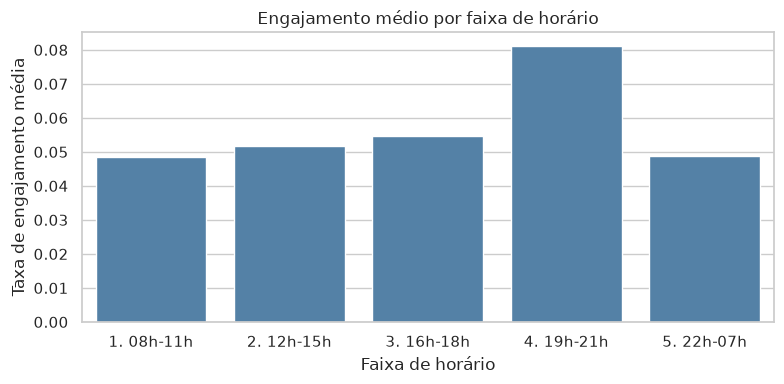

In [3]:
df = rodar(2)
display(df)

plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="faixa_horario", y="engajamento_medio", color="steelblue")
plt.title("Engajamento médio por faixa de horário")
plt.ylabel("Taxa de engajamento média")
plt.xlabel("Faixa de horário")
plt.tight_layout()
plt.savefig(PASTA_IMG / "engajamento_por_horario.png", dpi=120)
plt.show()

**Conclusão:** posts publicados entre 19h e 21h têm o maior engajamento (~8,1% contra ~5% nas outras
faixas) e também o maior alcance médio. Foi também a faixa em que mais se publicou.

## 3. Como o alcance evoluiu por semana?

,canal,semana_iso,posts,alcance_total,alcance_medio_por_post,alcance_semana_anterior
0,Instagram,2026-W28,13,74090,5699.0,NaN
1,Instagram,2026-W29,17,100639,5920.0,74090.0
2,Instagram,2026-W30,18,103959,5776.0,100639.0
3,Instagram,2026-W31,16,83968,5248.0,103959.0
4,Instagram,2026-W32,15,84642,5643.0,83968.0
5,Instagram,2026-W33,17,119502,7030.0,84642.0


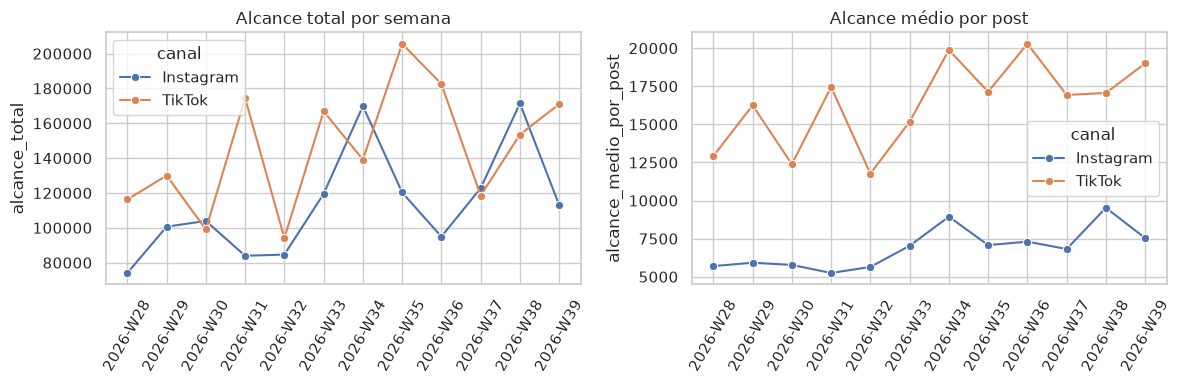

,canal,4_primeiras_semanas,4_ultimas_semanas,variacao_%
0,Instagram,5661,7796,37.7
1,TikTok,14750,18319,24.2


In [4]:
df = rodar(3)
display(df.head(6))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=df, x="semana_iso", y="alcance_total", hue="canal", marker="o", ax=eixos[0])
eixos[0].set_title("Alcance total por semana")
sns.lineplot(data=df, x="semana_iso", y="alcance_medio_por_post", hue="canal", marker="o", ax=eixos[1])
eixos[1].set_title("Alcance médio por post")
for eixo in eixos:
    eixo.tick_params(axis="x", rotation=60)
    eixo.set_xlabel("")
plt.tight_layout()
plt.show()

# Número para sustentar a tendência: média das 4 primeiras semanas x 4 últimas, por canal
linhas = []
for canal, g in df.groupby("canal"):
    g = g.sort_values("semana_iso")
    inicio = g["alcance_medio_por_post"].iloc[:4].mean()
    fim = g["alcance_medio_por_post"].iloc[-4:].mean()
    linhas.append({"canal": canal, "4_primeiras_semanas": round(inicio),
                   "4_ultimas_semanas": round(fim), "variacao_%": round((fim / inicio - 1) * 100, 1)})
display(pd.DataFrame(linhas))

**Conclusão:** o alcance total oscila bastante porque o número de posts muda de semana para semana.
O alcance médio por post sobe: comparando as 4 primeiras com as 4 últimas semanas, cresceu cerca de
38% no Instagram (5.661 para 7.796) e 24% no TikTok (14.750 para 18.319).

## 4. Engajamento por tema

,tema,posts,alcance_medio,engajamento_medio
0,Humor,64,13446.0,0.0840
1,Educativo,47,12256.0,0.0749
2,Bastidores,64,9331.0,0.0618
3,Lançamento,64,8510.0,0.0576
4,Promoção,64,8313.0,0.0491


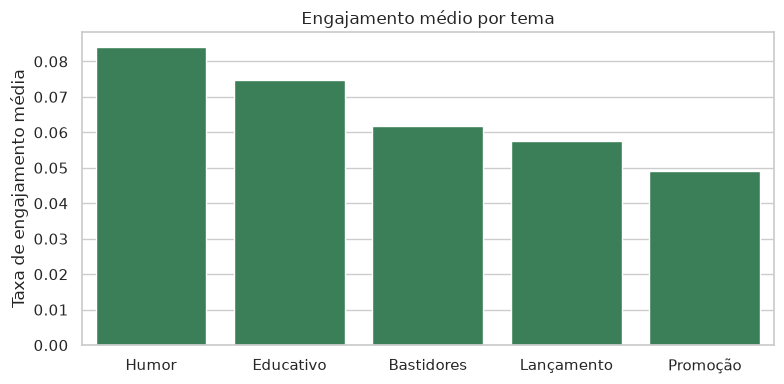

In [5]:
df = rodar(5)
display(df)

plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="tema", y="engajamento_medio", color="seagreen")
plt.title("Engajamento médio por tema")
plt.ylabel("Taxa de engajamento média")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Conclusão:** Humor e Educativo lideram em engajamento, e Promoção é o tema que menos engaja.
Vale lembrar que o tema se mistura com o formato e o horário, então esta comparação não isola o efeito do tema.

## 5. Instagram x TikTok

,canal,posts,alcance_medio,engajamento_sem_salvos,engajamento_geral,cliques_total
0,Instagram,196,6935.0,0.0461,0.0592,18193
1,TikTok,107,16367.0,0.0833,0.0592,21324


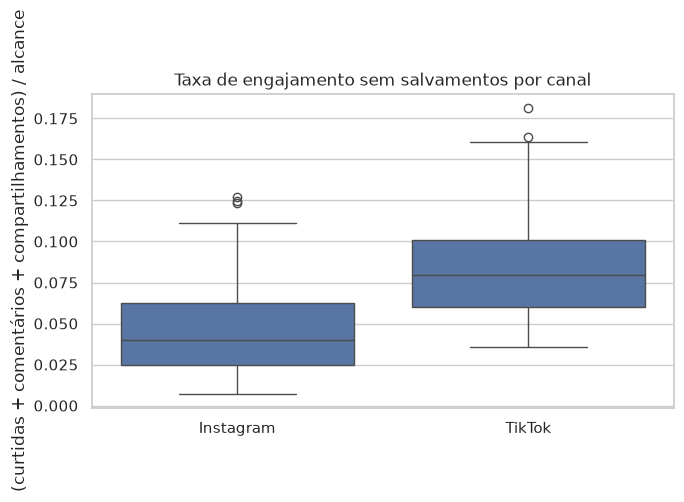

In [6]:
display(rodar(6))

# O TikTok não exporta salvamentos, então comparamos a taxa SEM salvamentos
plt.figure(figsize=(7, 4))
sns.boxplot(data=posts, x="canal", y="taxa_engajamento_sem_salvos")
plt.title("Taxa de engajamento sem salvamentos por canal")
plt.ylabel("(curtidas + comentários + compartilhamentos) / alcance")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Conclusão:** na taxa comparável (sem salvamentos), o TikTok engaja ~8,3% contra ~4,6% do Instagram,
e tem alcance médio mais que o dobro (16.367 contra 6.935). Parte da diferença vem do mix de formatos:
o TikTok só tem vídeo, que é o formato que mais engaja, enquanto o Instagram mistura Imagem e Stories.

## 6. Top 10 posts e dia da semana

In [7]:
display(rodar(4))
display(rodar(7))

,canal,id_post,data,formato,tema,alcance,taxa_engajamento
0,TikTok,P0047,2026-08-06,Vídeo,Humor,20752,0.1812
1,TikTok,P0015,2026-07-13,Vídeo,Humor,27201,0.1638
2,TikTok,P0087,2026-09-04,Vídeo,Educativo,23620,0.1603
3,TikTok,P0099,2026-09-08,Vídeo,Humor,20064,0.1515
4,TikTok,P0079,2026-08-24,Vídeo,Educativo,18908,0.1513
5,Instagram,P0138,2026-08-29,Carrossel,Humor,9093,0.1422
6,TikTok,P0065,2026-08-19,Vídeo,Bastidores,27909,0.1422
7,Instagram,P0072,2026-08-06,Reels,Humor,15759,0.1411
8,Instagram,P0177,2026-09-19,Reels,Humor,21765,0.1387
9,TikTok,P0114,2026-09-24,Vídeo,Humor,25139,0.1372


,dia_semana,posts,engajamento_medio
0,quinta,45,0.0677
1,sexta,44,0.0669
2,segunda,48,0.0648
3,domingo,40,0.0648
4,quarta,47,0.0645
5,terça,36,0.0630
6,sábado,43,0.0624


**Conclusão:** o top 10 é dominado por vídeos do TikTok e Reels do tema Humor. Entre os dias da
semana quase não há diferença de engajamento, então o dia parece importar menos que formato e horário.

## Conclusões

- **Formato:** vídeos curtos (Reels e TikTok) engajam cerca de 2 a 4 vezes mais que Imagem e Stories.
- **Horário:** publicar entre 19h e 21h dá mais alcance e mais engajamento.
- **Tema:** Humor e Educativo se destacam; Promoção é o mais fraco.
- **Dia da semana:** sem diferença relevante.
- **Tendência:** o alcance médio por post cresce ao longo das semanas.

Recomendação (para esta marca fictícia): priorizar vídeos curtos no horário nobre.

## Limitações

- Os dados são **sintéticos**: os padrões foram colocados de propósito pelo gerador, então
  aqui eles aparecem "limpos" demais. Em dados reais o efeito seria menor e mais ruidoso.
- Apenas 12 semanas e ~300 posts: não dá para falar em sazonalidade.
- As análises são descritivas (médias). Não testei significância estatística nem controlei
  fatores juntos (ex.: formato e horário ao mesmo tempo).
- A taxa de engajamento usa o alcance como denominador. Como o TikTok não tem salvamentos, a comparação
  entre canais usa a taxa sem salvamentos; as demais seções usam a taxa completa (salvamentos ausentes = 0).
- Linhas inválidas (cerca de 15% do total, incluindo duplicadas) foram descartadas na validação.